# Kumo Tabular como modelo desafiante (T2.3 / F2·4)

Bancada de trabalho da T2.3. O **Kumo Tabular** (NVIDIA, Hugging Face Hub, Apache-2.0) é um modelo
tabular pré-treinado: não se treina nos nossos dados, recebe as altas rotuladas como *contexto* no momento
da previsão (Lab W5_1). Aqui é **desafiante** do HistGradientBoosting v1 (D17): não o substitui, não entra
na app nem em `models/`. Conclusões e decisão em [docs/anexo_kumo_tabular.md](../docs/anexo_kumo_tabular.md).

Regras (iguais às da fase 2):
- os mesmos 5 folds por doente (D13); **o teste não se abre**: só previsões OOF;
- as mesmas 34 features (D15), mas em bruto: sem `build_preprocessor` nem one-hot (o Kumo trata as
  categóricas e os missing); sem `encounter_id` nem `patient_nbr` (D11);
- @k só nas altas elegíveis (D21), como no notebook 04;
- o contexto é uma amostra estratificada pelo target, tirada **só do treino do fold**.

**Ambiente:** `.venv-kumo` (ver `requirements-kumo.txt`) com GPU, ou Colab com *Runtime → T4 GPU*.
Sem GPU, as corridas grandes recusam-se a correr (demorariam horas).

In [1]:
# Colab: clonar o repositório e preparar os dados. Localmente não faz nada.
import sys
if "google.colab" in sys.modules:
    import os
    REPO, BRANCH = "https://github.com/EDSB26G11/Bootcamp_Projetos.git", "feature/t2-3-kumo-challenger"
    # Repositório privado: usar https://<token>@github.com/... ou fazer upload do repositório em zip.
    if not os.path.exists("Bootcamp_Projetos"):
        !git clone -q -b {BRANCH} {REPO}
    %cd Bootcamp_Projetos
    %pip install -q -r requirements-kumo.txt
    # data/raw e data/splits são versionados; data/processed gera-se (ou faz-se upload do CSV).
    if not os.path.exists("data/processed/diabetic_data_clean.csv"):
        !python -m src.data_preparation

In [2]:
import os
import platform
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", message=r"(?s).*HF_TOKEN")  # os pesos são públicos

from src.data.population import follow_up_eligible
from src.data.split import SEED
from src.models.baselines import candidate_models, logistic_regression
from src.models.evaluate import cv_predict, score_metrics
from src.models.kumo import KumoTabularClassifier, eligible_at_k, kumo_cv, stratified_context
from src.pipeline import cv_splits, load_model_data

data = load_model_data()
SPLITS = cv_splits(data)
ELIG = follow_up_eligible(data.X_train).to_numpy()
FIG, REP = ROOT / "reports" / "figures", ROOT / "reports"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUN_ON_CPU = False  # True só para experimentar com contextos pequenos
if DEVICE == "cpu" and not RUN_ON_CPU:
    raise RuntimeError("Sem GPU. No Colab: Runtime → Change runtime type → T4 GPU.")
HARDWARE = torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor()
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEVICE == "cuda" else np.nan
print(f"{DEVICE}: {HARDWARE} ({GPU_GB:.1f} GB) | torch {torch.__version__}")
print(f"treino {len(data.X_train):,} encontros | {data.X_train.shape[1]} features | "
      f"elegíveis {ELIG.mean():.1%}")

cuda: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GB) | torch 2.11.0+cu128
treino 80,041 encontros | 34 features | elegíveis 65.5%


## 1. Referências: HGB v1 e regressão logística nas mesmas OOF

O `reports/experiments.csv` tem as @k calculadas em todas as altas. Para comparar nas altas elegíveis
(D21), recalculam-se as OOF dos dois modelos com `cv_predict` (os mesmos folds; nada se regista: as
corridas já lá estão). A PR-AUC, a ROC-AUC e o Brier são os mesmos do registo.

In [3]:
def fold_table(oof) -> pd.DataFrame:
    """Métricas por fold a partir das OOF: todas as altas + @k nas elegíveis."""
    rows = []
    for k, (_, va) in enumerate(SPLITS):
        y, s = data.y_train.iloc[va], np.asarray(oof)[va]
        rows.append({"fold": k, **score_metrics(y, s), **eligible_at_k(y, s, ELIG[va])})
    return pd.DataFrame(rows).set_index("fold")

REF, OOF, REF_SECONDS = {}, {}, {}
for name, model in {"HGB v1": candidate_models()["hist_gradient_boosting"],
                    "logreg": logistic_regression()}.items():
    t0 = time.perf_counter()
    _, _, OOF[name] = cv_predict(model, data)
    REF_SECONDS[name] = (time.perf_counter() - t0) / len(SPLITS)  # inclui as métricas de treino do cv_predict
    REF[name] = fold_table(OOF[name])
REF["HGB v1"][["pr_auc", "roc_auc", "brier", "recall_at_10_eleg", "recall_at_20_eleg"]].agg(["mean", "std"]).round(4)

,pr_auc,roc_auc,brier,recall_at_10_eleg,recall_at_20_eleg
mean,0.2345,0.6769,0.0953,0.2521,0.4015
std,0.0081,0.0075,0.0005,0.0077,0.0140


## 2. Kumo Tabular nos 5 folds, com 3 tamanhos de contexto

O treino de cada fold (~64k encontros) é maior do que as tabelas do pré-treino (até ~60k linhas). Usa-se uma
amostra estratificada do treino do fold com 10k, 30k e 55k encontros. Cada tamanho fica registado em
`reports/experiments.csv` (só a linha de validação; a nota explica porquê). Modelo `small` (28 M parâmetros),
`num_estimators=4`, seed 42 no gerador.

In [4]:
CONTEXT_SIZES = [10_000, 30_000, 55_000]
KUMO, KUMO_OOF = {}, {}
for n in CONTEXT_SIZES:
    name = f"kumo_tabular_small ctx={n // 1000}k"
    model = KumoTabularClassifier(max_context=n, size="small", device=DEVICE)
    KUMO[name], KUMO_OOF[name] = kumo_cv(name, model, data, notes="T2.3/F2·4 desafiante do v1.")
    print(f"{name}: PR-AUC {KUMO[name]['pr_auc'].mean():.4f} ± {KUMO[name]['pr_auc'].std():.4f} "
          f"| {KUMO[name]['seconds'].mean():.0f} s/fold | pico {KUMO[name]['gpu_peak_gb'].max():.2f} GB")

pd.concat(KUMO, names=["modelo"]).to_csv(REP / "kumo_cv_folds.csv")

C:\Users\afili\OneDrive\NOVA IMS - PG_EDSA\EDS Bootcamp\Projeto\Bootcamp_Projetos\.venv-kumo\Lib\site-packages\sdm\tensor\string.py:502: RuntimeWarning: Falling back to a CPU-based string sort because cuDF is not installed. Install cuDF to enable faster CUDA-based string sorting without device synchronization. This warning will be suppressed for the remainder of this process.
  warn_once(
C:\Users\afili\OneDrive\NOVA IMS - PG_EDSA\EDS Bootcamp\Projeto\Bootcamp_Projetos\.venv-kumo\Lib\site-packages\sdm\relational\join.py:73: RuntimeWarning: Falling back to a CPU-based join because cuDF is not installed. Install cuDF to enable faster CUDA-based joins without device synchronization. This warning will be suppressed for the remainder of this process.
  warn_once(


kumo_tabular_small ctx=10k: PR-AUC 0.2162 ± 0.0042 | 16 s/fold | pico 1.05 GB


kumo_tabular_small ctx=30k: PR-AUC 0.2262 ± 0.0061 | 51 s/fold | pico 1.44 GB


kumo_tabular_small ctx=55k: PR-AUC 0.2331 ± 0.0052 | 129 s/fold | pico 1.94 GB


### 2.1 Verificação de fuga por doente

Feita sempre, não só se a PR-AUC sair alta: (1) nenhum `patient_nbr` do contexto aparece na validação do
fold; (2) quantas linhas de validação têm uma linha igual (nas 34 features) no contexto. Linhas iguais de
doentes diferentes podem existir; o que não pode haver é o mesmo doente.

In [5]:
leak = []
for k, (tr, va) in enumerate(SPLITS):
    m = KumoTabularClassifier(max_context=max(CONTEXT_SIZES)).fit(data.X_train.iloc[tr], data.y_train.iloc[tr])
    ctx_patients = set(data.groups_train.loc[m.context_index_])
    va_patients = set(data.groups_train.iloc[va])
    ctx_rows = set(map(tuple, m.context_X_.astype(str).to_numpy()))
    same_row = np.mean([tuple(r) in ctx_rows for r in data.X_train.iloc[va].astype(str).to_numpy()])
    leak.append({"fold": k, "doentes_em_comum": len(ctx_patients & va_patients),
                 "validação_com_linha_igual_no_contexto": same_row})
leak = pd.DataFrame(leak).set_index("fold")
assert leak["doentes_em_comum"].eq(0).all()
leak.round(4)

,doentes_em_comum,validação_com_linha_igual_no_contexto
fold,,
0,0,0.0000
1,0,0.0000
2,0,0.0001
3,0,0.0000
4,0,0.0001


### 2.2 Fold a fold e média ± desvio, lado a lado com o HGB v1 e a logreg

PR-AUC é a métrica principal; @k nas altas elegíveis (D21). Uma diferença menor do que o desvio entre folds
não é uma diferença (regra 5 de `modelacao_base.md`). O melhor tamanho de contexto é escolhido nestes mesmos
folds, o que favorece ligeiramente o Kumo.

In [6]:
ALL = {**REF, **KUMO}
COLS = ["pr_auc", "roc_auc", "brier", "recall_at_10_eleg", "precision_at_10_eleg",
        "recall_at_20_eleg", "precision_at_20_eleg"]
summary = pd.DataFrame({name: {f"{c} {s}": getattr(t[c], s)() for c in COLS for s in ("mean", "std")}
                        for name, t in ALL.items()}).T
summary.to_csv(REP / "kumo_vs_v1_summary.csv")
summary.round(4)

,pr_auc mean,pr_auc std,roc_auc mean,roc_auc std,brier mean,brier std,recall_at_10_eleg mean,recall_at_10_eleg std,precision_at_10_eleg mean,precision_at_10_eleg std,recall_at_20_eleg mean,recall_at_20_eleg std,precision_at_20_eleg mean,precision_at_20_eleg std
HGB v1,0.2345,0.0081,0.6769,0.0075,0.0953,0.0005,0.2521,0.0077,0.2409,0.0049,0.4015,0.0140,0.1918,0.0036
logreg,0.2105,0.0080,0.6644,0.0082,0.0965,0.0005,0.2447,0.0128,0.2338,0.0107,0.3945,0.0135,0.1884,0.0048
kumo_tabular_small ctx=10k,0.2162,0.0042,0.6634,0.0076,0.0963,0.0003,0.2483,0.0099,0.2372,0.0081,0.3919,0.0163,0.1872,0.0056
kumo_tabular_small ctx=30k,0.2262,0.0061,0.6711,0.0068,0.0958,0.0003,0.2483,0.0107,0.2372,0.0072,0.3990,0.0172,0.1906,0.0071
kumo_tabular_small ctx=55k,0.2331,0.0052,0.6758,0.0064,0.0954,0.0004,0.2511,0.0094,0.2399,0.0073,0.4037,0.0189,0.1928,0.0074


In [7]:
BEST = max(KUMO, key=lambda n: KUMO[n]["pr_auc"].mean())
by_fold = pd.DataFrame({name: t["pr_auc"] for name, t in ALL.items()})
delta = KUMO[BEST][COLS] - REF["HGB v1"][COLS]
by_fold["Δ PR-AUC (melhor Kumo − HGB)"] = delta["pr_auc"]
print(f"Melhor contexto: {BEST}")
print("Folds em que o Kumo ganha ao HGB:",
      {c: int((delta[c] < 0).sum() if c == "brier" else (delta[c] > 0).sum()) for c in COLS})
print("Δ médio ± desvio:", {c: f"{delta[c].mean():+.4f} ± {delta[c].std():.4f}" for c in COLS})
if KUMO[BEST]["pr_auc"].mean() > 0.26:
    print("ATENÇÃO: PR-AUC > 0,26. Rever a fuga por doente (2.1) antes de reportar.")
by_fold.round(4)

Melhor contexto: kumo_tabular_small ctx=55k
Folds em que o Kumo ganha ao HGB: {'pr_auc': 1, 'roc_auc': 1, 'brier': 1, 'recall_at_10_eleg': 2, 'precision_at_10_eleg': 2, 'recall_at_20_eleg': 3, 'precision_at_20_eleg': 3}
Δ médio ± desvio: {'pr_auc': '-0.0013 ± 0.0043', 'roc_auc': '-0.0011 ± 0.0012', 'brier': '+0.0001 ± 0.0002', 'recall_at_10_eleg': '-0.0010 ± 0.0080', 'precision_at_10_eleg': '-0.0010 ± 0.0076', 'recall_at_20_eleg': '+0.0022 ± 0.0106', 'precision_at_20_eleg': '+0.0011 ± 0.0050'}


,HGB v1,logreg,kumo_tabular_small ctx=10k,kumo_tabular_small ctx=30k,kumo_tabular_small ctx=55k,Δ PR-AUC (melhor Kumo − HGB)
fold,,,,,,
0,0.2234,0.1967,0.2092,0.2180,0.2286,0.0052
1,0.2431,0.2162,0.2198,0.2283,0.2363,-0.0067
2,0.2414,0.2131,0.2186,0.2345,0.2403,-0.0011
3,0.2341,0.2158,0.2182,0.2272,0.2325,-0.0016
4,0.2303,0.2107,0.2154,0.2231,0.2280,-0.0023


## 3. Poucos dados rotulados

Diz-se que os modelos pré-treinados ajudam mais quando há poucos rótulos. Testa-se com 500, 2 000, 10 000 e o
máximo (55 000) encontros rotulados, em 2 folds. Os **mesmos** encontros (amostra estratificada do treino do
fold) servem para treinar a logreg e de contexto ao Kumo; a validação é o fold inteiro.

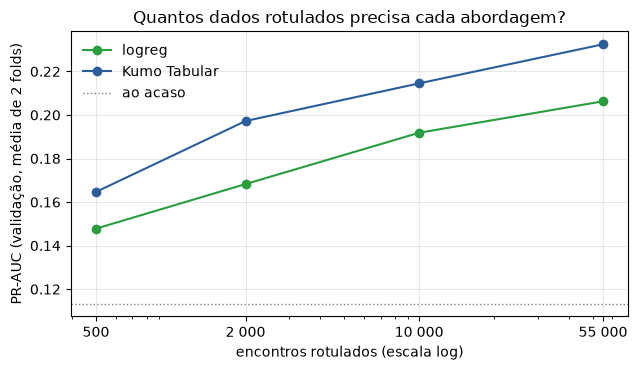

modelo,Kumo Tabular,logreg
rotulados,,
500,0.1647,0.1478
2000,0.1972,0.1683
10000,0.2145,0.1918
55000,0.2325,0.2063


In [8]:
CURVE_SIZES, CURVE_FOLDS = [500, 2_000, 10_000, 55_000], [0, 1]
rows = []
for k in CURVE_FOLDS:
    tr, va = SPLITS[k]
    for n in CURVE_SIZES:
        lab = tr[stratified_context(data.y_train.iloc[tr], n, SEED)]
        X_lab, y_lab = data.X_train.iloc[lab], data.y_train.iloc[lab]
        y_va = data.y_train.iloc[va]
        for name, model in {"logreg": logistic_regression(),
                            "Kumo Tabular": KumoTabularClassifier(max_context=n, device=DEVICE)}.items():
            s = model.fit(X_lab, y_lab).predict_proba(data.X_train.iloc[va])[:, 1]
            rows.append({"fold": k, "rotulados": n, "modelo": name, "pr_auc": score_metrics(y_va, s)["pr_auc"]})
curve_raw = pd.DataFrame(rows)
curve_raw.to_csv(REP / "kumo_learning_curve.csv", index=False)
curve = curve_raw.groupby(["rotulados", "modelo"])["pr_auc"].mean().unstack()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, color in (("logreg", "#2a9d3f"), ("Kumo Tabular", "#2c5d9b")):
    ax.plot(curve.index, curve[name], marker="o", color=color, label=name)
ax.axhline(data.y_train.mean(), color="grey", ls=":", lw=1, label="ao acaso")
ax.set_xscale("log")
ax.set_xticks(CURVE_SIZES, [f"{s:,}".replace(",", " ") for s in CURVE_SIZES])
ax.set(xlabel="encontros rotulados (escala log)", ylabel="PR-AUC (validação, média de 2 folds)",
       title="Quantos dados rotulados precisa cada abordagem?")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "kumo_learning_curve.png", dpi=150)
plt.show()
curve.round(4)

## 4. Custos

O Kumo não tem fase de treino: o custo está todo na previsão, e **o contexto com os dados dos doentes tem de
viajar com o modelo** (a app teria de guardar e proteger dezenas de milhares de altas rotuladas, não só um
ficheiro de modelo).

In [9]:
v1_file = ROOT / "models" / "v1" / "model.skops"
costs = []
for name, t in KUMO.items():
    n = int(t["n_context"].iloc[0])
    m = KumoTabularClassifier(max_context=n).fit(data.X_train.iloc[SPLITS[0][0]], data.y_train.iloc[SPLITS[0][0]])
    ctx_csv_mb = len(m.context_X_.assign(target=m.context_y_).to_csv(index=False).encode()) / 2**20
    costs.append({"modelo": name, "hardware": HARDWARE, "contexto (encontros)": n,
                  "s por fold (previsão)": t["seconds"].mean(),
                  "ms por 1 000 previsões": 1000 * t["seconds"].mean() / t["n_query"].mean() * 1000,
                  "memória de pico GPU (GB)": t["gpu_peak_gb"].max(),
                  "dados de doentes a enviar com o modelo (MB, CSV)": ctx_csv_mb})
for name, s in REF_SECONDS.items():
    costs.append({"modelo": name, "hardware": f"CPU ({platform.processor()})", "contexto (encontros)": 0,
                  "s por fold (treino + previsão)": s,
                  "dados de doentes a enviar com o modelo (MB, CSV)": 0.0})
costs = pd.DataFrame(costs).set_index("modelo")
costs.to_csv(REP / "kumo_costs.csv")
print(f"Pesos do Kumo small: ~110 MB (Hugging Face Hub). "
      f"Modelo v1 em skops: {v1_file.stat().st_size / 2**20:.1f} MB" if v1_file.exists() else "")
costs.round(2)

Pesos do Kumo small: ~110 MB (Hugging Face Hub). Modelo v1 em skops: 2.9 MB


,hardware,contexto (encontros),s por fold (previsão),ms por 1 000 previsões,memória de pico GPU (GB),"dados de doentes a enviar com o modelo (MB, CSV)",s por fold (treino + previsão)
modelo,,,,,,,
kumo_tabular_small ctx=10k,NVIDIA GeForce RTX 4050 Laptop GPU,10000,15.63,976.39,1.05,1.81,NaN
kumo_tabular_small ctx=30k,NVIDIA GeForce RTX 4050 Laptop GPU,30000,51.20,3198.57,1.44,5.44,NaN
kumo_tabular_small ctx=55k,NVIDIA GeForce RTX 4050 Laptop GPU,55000,128.71,8040.38,1.94,9.96,NaN
HGB v1,"CPU (Intel64 Family 6 Model 154 Stepping 3, Ge...",0,NaN,NaN,NaN,0.00,9.21
logreg,"CPU (Intel64 Family 6 Model 154 Stepping 3, Ge...",0,NaN,NaN,NaN,0.00,2.92


## 5. Explicabilidade: importância por permutação (D19)

`sklearn.inspection.permutation_importance` com a PR-AUC, numa amostra estratificada de 3 000 encontros da
validação do fold 0, contexto de 10k (para o custo caber: 34 colunas × 3 repetições = 102 previsões), comparada
com `reports/permutation_importance_v1.csv` (HGB v1, 5 folds, validação inteira). **Depende do contexto:**
com outro contexto, a mesma alta pode ter outro risco e as importâncias mudam; a do v1 é uma propriedade de um
modelo fixo. Com ~340 positivos, as importâncias pequenas são ruído.

In [10]:
from sklearn.inspection import permutation_importance

tr, va = SPLITS[0]
va_s = va[stratified_context(data.y_train.iloc[va], 3_000, SEED)]
pi_model = KumoTabularClassifier(max_context=10_000, device=DEVICE).fit(data.X_train.iloc[tr], data.y_train.iloc[tr])
t0 = time.perf_counter()
r = permutation_importance(pi_model, data.X_train.iloc[va_s], data.y_train.iloc[va_s],
                           scoring="average_precision", n_repeats=3, random_state=SEED)
pi_seconds = time.perf_counter() - t0
pi_kumo = (pd.DataFrame({"importance": r.importances_mean, "std": r.importances_std}, index=data.X_train.columns)
           .sort_values("importance", ascending=False))
pi_kumo.to_csv(REP / "permutation_importance_kumo.csv")

pi_v1 = pd.read_csv(REP / "permutation_importance_v1.csv", index_col=0)
cmp = pd.DataFrame({"kumo": pi_kumo["importance"], "kumo_rank": pi_kumo["importance"].rank(ascending=False),
                    "v1": pi_v1["importance"], "v1_rank": pi_v1["importance"].rank(ascending=False)})
rho = spearmanr(cmp["kumo"], cmp["v1"]).statistic
top10 = len(set(pi_kumo.index[:10]) & set(pi_v1.index[:10]))
print(f"{pi_seconds / 60:.1f} min | Spearman entre as ordens: {rho:.2f} | top-10 em comum: {top10}/10")
cmp.sort_values("kumo_rank").head(15).round(4)

30.5 min | Spearman entre as ordens: 0.43 | top-10 em comum: 7/10


,kumo,kumo_rank,v1,v1_rank
number_inpatient,0.0652,1.0,0.0519,1.0
discharge_disposition_id_desc,0.0147,2.0,0.0496,2.0
n_visits_prior,0.0086,3.0,0.0052,5.0
diabetes_complicated,0.0020,4.0,0.0026,8.0
number_outpatient,0.0020,5.0,0.0007,23.0
payer_code,0.0018,6.0,0.0077,3.0
medical_specialty,0.0013,7.0,0.0056,4.0
age_band,0.0012,8.0,0.0024,10.0
n_meds_down,0.0007,9.0,0.0006,24.0
n_meds_up,0.0006,10.0,0.0000,31.0


## 6. O que a evidência diz

Ler com as três perguntas do Lab W5_1: (1) o Kumo ordena melhor do que o v1? (secção 2.2); (2) em todos os
folds ou só em média? (Δ fold a fold); (3) a comparação depende de quantos rótulos há? (secção 3). Depois
pesar contra os custos (secção 4) e a explicabilidade (secção 5). A decisão fica em
[docs/anexo_kumo_tabular.md](../docs/anexo_kumo_tabular.md) e na linha de D23 em `docs/decisions.md`.